# Principal Component Analysis (PCA)

## 1. Load the dataset and scale the features

In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

working_directory = Path.cwd()
dataset_candidates = [
    candidate
    for directory in (working_directory, *working_directory.parents)
    for candidate in (directory / "iris.csv", directory / "Task22" / "iris.csv")
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    iris = load_iris(as_frame=True)
    dataset = iris.data.copy()
    dataset["species"] = iris.target.map(dict(enumerate(iris.target_names)))
    print("iris.csv was not found; using scikit-learn's built-in Iris dataset.")
else:
    dataset = pd.read_csv(dataset_path)
    print(f"Loaded dataset from: {dataset_path}")
feature_columns = [column for column in dataset.columns if column != "species"]
features = dataset[feature_columns]
labels = dataset["species"]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)
scaled_dataset = pd.DataFrame(scaled_features, columns=feature_columns)
scaled_dataset["species"] = labels

print(f"Dataset shape: {dataset.shape[0]} rows, {len(feature_columns)} features")
display(scaled_dataset)

iris.csv was not found; using scikit-learn's built-in Iris dataset.
Dataset shape: 150 rows, 4 features


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,-0.900681,1.019004,-1.340227,-1.315444,setosa
1,-1.143017,-0.131979,-1.340227,-1.315444,setosa
2,-1.385353,0.328414,-1.397064,-1.315444,setosa
3,-1.506521,0.098217,-1.283389,-1.315444,setosa
4,-1.021849,1.249201,-1.340227,-1.315444,setosa
...,...,...,...,...,...
145,1.038005,-0.131979,0.819596,1.448832,virginica
146,0.553333,-1.282963,0.705921,0.922303,virginica
147,0.795669,-0.131979,0.819596,1.053935,virginica
148,0.432165,0.788808,0.933271,1.448832,virginica


## 2. Apply PCA and review explained variance

In [8]:
pca = PCA()
transformed_features = pca.fit_transform(scaled_features)
component_columns = [f"PC{number}" for number in range(1, transformed_features.shape[1] + 1)]

transformed_dataset = pd.DataFrame(transformed_features, columns=component_columns)
transformed_dataset["species"] = labels

explained_variance = pd.DataFrame({
    "component": component_columns,
    "explained_variance_ratio": pca.explained_variance_ratio_,
    "cumulative_explained_variance": pca.explained_variance_ratio_.cumsum(),
})

display(transformed_dataset)
display(explained_variance.round(4))
print(f"Variance retained by the first two components: {pca.explained_variance_ratio_[:2].sum():.2%}")

,PC1,PC2,PC3,PC4,species
0,-2.264703,0.480027,0.127706,-0.024168,setosa
1,-2.080961,-0.674134,0.234609,-0.103007,setosa
2,-2.364229,-0.341908,-0.044201,-0.028377,setosa
3,-2.299384,-0.597395,-0.091290,0.065956,setosa
4,-2.389842,0.646835,-0.015738,0.035923,setosa
...,...,...,...,...,...
145,1.870503,0.386966,-0.256274,-0.389257,virginica
146,1.564580,-0.896687,0.026371,-0.220192,virginica
147,1.521170,0.269069,-0.180178,-0.119171,virginica
148,1.372788,1.011254,-0.933395,-0.026129,virginica


,component,explained_variance_ratio,cumulative_explained_variance
0,PC1,0.7296,0.7296
1,PC2,0.2285,0.9581
2,PC3,0.0367,0.9948
3,PC4,0.0052,1.0000


Variance retained by the first two components: 95.81%


## 3. Visualize the data in two dimensions

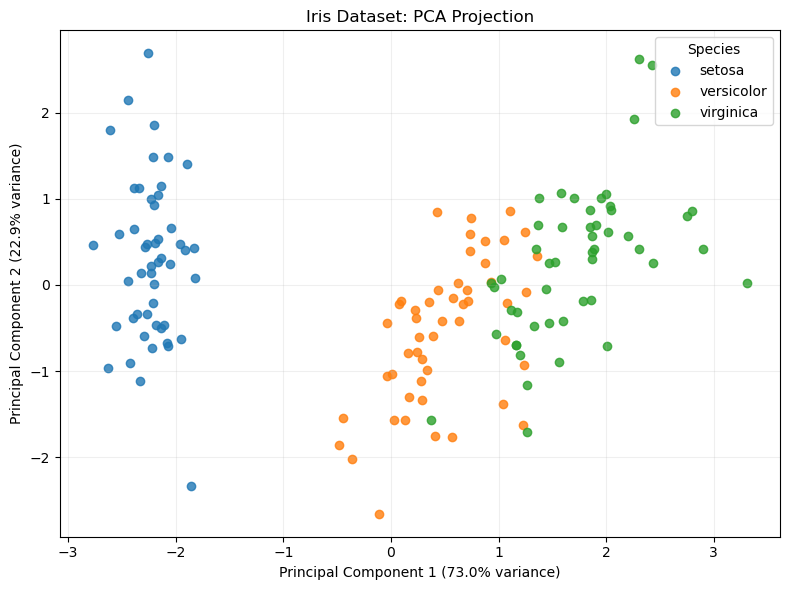

In [9]:
fig, ax = plt.subplots(figsize=(8, 6))
for species in sorted(labels.unique()):
    selected = labels == species
    ax.scatter(
        transformed_features[selected, 0],
        transformed_features[selected, 1],
        label=species,
        alpha=0.8,
    )

variance = pca.explained_variance_ratio_
ax.set_title("Iris Dataset: PCA Projection")
ax.set_xlabel(f"Principal Component 1 ({variance[0]:.1%} variance)")
ax.set_ylabel(f"Principal Component 2 ({variance[1]:.1%} variance)")
ax.legend(title="Species")
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()